## 1. Data Ingestion and Preprocessing

In this section, we import the raw historical data from **Station 1413** and format it for subsequent time-series analysis. 

### Key Actions Performed:
* **File Ingestion:** Loaded the Excel spreadsheet while skipping the first row (`skiprows=1`) to filter out the file's main title and isolate the data table header.
* **Column Renaming:** Standardized headers to clean, concise English names (`datetime` and `q_m3s` for flow rate in cubic meters per second) to streamline data manipulation.
* **Datetime Normalization:** Converted the string timestamps into actual datetime objects using the specific format `%d/%m/%Y %H:%M`. We then applied `.dt.normalize()` to strip away the hourly timestamps (e.g., setting hours to `00:00`), keeping only the calendar date.
* **Data Verification:** Printed basic dataset structures, dimensions, and date ranges to ensure accuracy. 

> **Note on Data Completeness:** The total row count represents the length of the dataset matrix. It confirms the structure is loaded, but does not guarantee every calendar day within the period contains valid, non-null measurements.


In [16]:
import pandas as pd 

# Load raw dataset and fix headers
raw = pd.read_excel("../data/raw/Historicos-Estacion 1413.xlsx", skiprows=1)
raw.columns = ["datetime", "q_m3s"]

# Parse and normalize timestamps to daily dates
raw["date"] = pd.to_datetime(raw["datetime"], format="%d/%m/%Y %H:%M").dt.normalize() 

# Metadata and formatting check
raw.info() 
display(raw.head())   

# Temporal range and structural properties
print('First recorded date: ', raw["date"].min())
print('Last recorded date: ', raw["date"].max())
print("Rows:", len(raw))

<class 'pandas.DataFrame'>
RangeIndex: 25464 entries, 0 to 25463
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  25464 non-null  str           
 1   q_m3s     25464 non-null  float64       
 2   date      25464 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 596.9 KB


,datetime,q_m3s,date
0,01/07/1956 09:00,17.0,1956-07-01
1,02/07/1956 09:00,17.0,1956-07-02
2,03/07/1956 09:00,17.0,1956-07-03
3,04/07/1956 09:00,18.0,1956-07-04
4,05/07/1956 09:00,19.0,1956-07-05


First recorded date:  1956-07-01 00:00:00
Last recorded date:  2026-06-30 00:00:00
Rows: 25464


## 1.1 Time-series continuity and quality control

To assess the integrity of our historical records, we evaluate the dataset's continuity. We calculate the expected number of calendar days between the first and last recorded dates and cross-reference this against our row count to detect missing time-steps. Additionally, we need to check two things:
 1) We look for zero or negative values in column 'q_m3s': An error in the flow sensor could trigger a negative value, which is impossible.
 2) We look for repeated dates in column 'date': If there are repeated dates in said column, this would underestimate the actual number of missing days.

### Key Actions Performed:
* **Expected days:** Total number of calendar days spanned in the dataset.
* **Missing days:** The difference between the expected calendar days and the actual number of rows.
* **Repeated dates:** A repeated date could occupy the place of a missing date, underestimating the actual number of missing days. 
* **Percentage of missing days:** It is interesting to check this value, in order to determine if the raw dataset has a high number of missing days. 



In [17]:
# Determine the expected calendar days spanned
expected_days = (raw["date"].max() - raw["date"].min()).days + 1
print("Expected days:", expected_days)

# Determine the number of missing days
missing_days = expected_days - len(raw)
print("Missing days:", missing_days)

# Check if there are zero or negative values in column 'q_m3s'.
print("Zero or negative values:", (raw["q_m3s"] <= 0).sum())

# Check if there are duplicated dates in column 'date'
print("Duplicated dates:", raw["date"].duplicated().sum())

# Calculate the final percetange of missing days
print("Percentage of missing days:", round(missing_days/expected_days * 100,3), '%')


Expected days: 25567
Missing days: 103
Zero or negative values: 0
Duplicated dates: 0
Percentage of missing days: 0.403 %


## 1.2 Locating and sorting missing days 

After calculating the number of expected, missing, zero or negative and duplicated days, now it is necessary to determine where those missing days are located. In order to achieve this, we will create a range named 'full_calendar' which goes from the 1st to the last date recorded, with a frequency of 1 day. Then, we will determine the number of missing dates (stored in 'missing_dates'). After this, we check if the previous value stored in 'missing_days' (calculated doing: expected_days - len(raw)) equals missing_dates (obtained with the "range method").
Finally, we count and organize the missing dates, sorting them by year. 

### Key Actions Performed:
* **Range:** We create a range stored in 'full_calendar', that goes from the 1st to the last date, and with a daily frequency.
* **Quantity of missing dates:** Even though we already calculated the number of missing dates doing (expected_days - len(raw)), we need to check if the quantity of missing dates coming from both methods ("difference and range" methods) are the same.
* **Number of missing dates per year:** From all the missing dates obtained previously, we classify them by the year those "missing spaces" are located. 



In [18]:
# Create a range with start and end point, and frequency
full_calendar = pd.date_range(start= raw["date"].min() , end= raw["date"].max() ,freq= '1D')

# Identify the missing dates and obtain the quantity
missing_dates=full_calendar[~full_calendar.isin(raw['date'])]
print(missing_dates)
print('Quantity of missing dates: ',len(missing_dates))

# Check is missing_dates == missing_days
if len(missing_dates) == missing_days:
    print('Both values are equal')
else:
    print('Values are not equal ')

# Sort the missing dates by year
missing_dates.year.value_counts().sort_index()

DatetimeIndex(['1962-09-01', '1962-09-02', '1962-09-03', '1962-09-04',
               '1962-09-05', '1962-09-06', '1962-09-07', '1962-09-08',
               '1962-09-09', '1962-09-10',
               ...
               '1985-06-22', '1985-06-23', '1985-06-24', '1985-06-25',
               '1985-06-26', '1985-06-27', '1985-06-28', '1985-06-29',
               '1985-06-30', '2023-06-18'],
              dtype='datetime64[us]', length=103, freq=None)
Quantity of missing dates:  103
Both values are equal


1962    30
1970     2
1976    40
1985    30
2023     1
Name: count, dtype: int64

## 1.3 Interpolating missing days 

After locating and sorting the missing days, we need to use a linear interpolation model to fill the flow values of the missing dates (in other words, filling the "q_m3s values" of the missing dates). To achieve this, we follow the sequence:
 1) We define series "q" which makes the column 'date' the index of the table. 
 2) After, we force the table to have exactly the rows of a given index (using 'reindex'), which makes the missing dates to appear as 'NaN'. 
 3) The fact that the missing dates appear as 'NaN' is useful to create a flag called 'filled' which has 2 possible values: True / False. Incorporating a flag is necessary to differentiate the 'filled' values from the 'measured data'.
 4) Finally, we check the following:  A) There is 0 NaN after interpolating ; B) There are 103 filled dates ; C) Visual inspection of the filled gap [in this particular case: 1976-06-18:1976-08-02]

### Key Actions Performed:
* **Set index:** We define a series 'q' that correlates the values in column 'q_m3s' with the new index: 'date'.
* **Reindex:** By forcing the table to have exactly the rows of a given index, the rows related with the missing dates are created, and 'NaN' appears in them.
* **Interpolate:** Allows us to use a linear interpolation model to fill the flow values of the missing dates. We use the 'time' method, which interpolates based on the distance between the dates.



In [19]:
# Define series 'q' , which correlates the values in column 'q_m3s' with the new index: 'dates'
q = raw.set_index("date")["q_m3s"]

# Use reindex to generate the rows related with the missing dates
q = q.reindex(full_calendar)

# Create the flag 'filled' to recognize if the value is measured or interpolated
filled = q.isna()

# Use 'time' method for linear interpolation
q=q.interpolate(method="time")
print(q)    

# Verifications: 
print("NaN after interpolation:", q.isna().sum())   # must be 0 [means all NaN have been filled]
print("Filled days:", filled.sum())                  # must be 103 [missing dates]
display(q["1976-06-18":"1976-08-02"])                # look inside the longest gap to check if the interpolation was executed

1956-07-01    17.00
1956-07-02    17.00
1956-07-03    17.00
1956-07-04    18.00
1956-07-05    19.00
              ...  
2026-06-26    22.17
2026-06-27    22.14
2026-06-28    21.37
2026-06-29    21.72
2026-06-30    21.66
Freq: D, Name: q_m3s, Length: 25567, dtype: float64
NaN after interpolation: 0
Filled days: 103


1976-06-18    16.800000
1976-06-19    17.000000
1976-06-20    17.200000
1976-06-21    17.200000
1976-06-22    17.187805
1976-06-23    17.175610
1976-06-24    17.163415
1976-06-25    17.151220
1976-06-26    17.139024
1976-06-27    17.126829
1976-06-28    17.114634
1976-06-29    17.102439
1976-06-30    17.090244
1976-07-01    17.078049
1976-07-02    17.065854
1976-07-03    17.053659
1976-07-04    17.041463
1976-07-05    17.029268
1976-07-06    17.017073
1976-07-07    17.004878
1976-07-08    16.992683
1976-07-09    16.980488
1976-07-10    16.968293
1976-07-11    16.956098
1976-07-12    16.943902
1976-07-13    16.931707
1976-07-14    16.919512
1976-07-15    16.907317
1976-07-16    16.895122
1976-07-17    16.882927
1976-07-18    16.870732
1976-07-19    16.858537
1976-07-20    16.846341
1976-07-21    16.834146
1976-07-22    16.821951
1976-07-23    16.809756
1976-07-24    16.797561
1976-07-25    16.785366
1976-07-26    16.773171
1976-07-27    16.760976
1976-07-28    16.748780
1976-07-29    16

## 1.4 Plotting historical data

In this section, we import the matplotlib library and plot the date vs daily mean flow (m3/s) to visualize the historical data.

### Key Actions Performed:
* **Import Matplotlib:** Matplotlib is an open-source library for creating interactive data visualization resources. 
* **Fig parameters:** 14x4 fig size: wide format for a long series.
* **Data parameters:** There are 2 kind of points: A) Measured points (in blue, united by a line). B) Interpolated points (in red, shown as single points).
* **Axes:** 2 axes: 'Date' as the horizontal axis, and 'Daily mean flow (m³/s)' as the vertical axis
* **Rest of parameters:** Such as the plot title and legends.

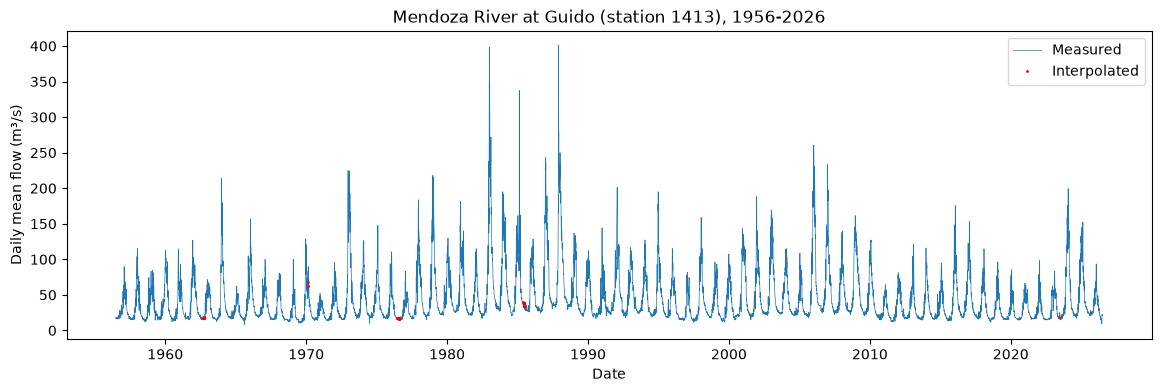

In [20]:
# Import matplotlib
import os
import matplotlib.pyplot as plt

# Create folder for images

os.makedirs("../docs/figures", exist_ok=True)

# Creating the graph
fig, ax = plt.subplots(figsize=(14,4))

# Define both kind of values, measured and interpolated
ax.plot(q.index, q, linewidth=0.5, label="Measured")
ax.plot(q[filled].index, q[filled], ".", color="red", markersize=2, label="Interpolated")

# Name both axes
ax.set_xlabel("Date")
ax.set_ylabel("Daily mean flow (m³/s)")

# Define set title and legend
ax.set_title("Mendoza River at Guido (station 1413), 1956-2026")
ax.legend()

fig.savefig("../docs/figures/daily_flow.png", dpi=150, bbox_inches="tight")

# Show graph
plt.show()

## 1.5 Determining wet and dry years

In this section, we determine various and useful parameters such as the means and medians of the different individual years and decades.
First, we obtain the annual average flow rate (mean), strictly from the complete calendar years (the first and last year,which are incomplete, will not be taken in account). Then, we sort those average flow rates and select the 5 wettest years.

After this, we can also calculate the mean of each decade and also sort these values. This will also give us useful information regarding the dry and wet decades. Added to this, the median of the average flow rates will be used as a threshold to determine if a particular year is considered as dry or wet. This means that we are going to be using our own criteria: If the average flow rate is less than the previously obtained median (lower half of the 69 average flows), the year will be considered as dry. Otherwise, it will be considered as wet. 

### Key Actions Performed:
* **Annual average flow rate, based on complete years:** For each complete year, the average flow rate is calculated. For the years at the ends of the series, it does not make sense to calculate the average flow rate.
* **Average flow rate per decade:** In the same way that the average flow rate was calculated for each full year, the same process is applied to the decades. This allows us to determine which decades are dry and which are wet.
* **median as a threshold and for dry/wet classification:** As previously explained, the median of the annual average flow rates is used as a threshold to determine whether a given year is dry or wet. If a year falls below this median, it is considered to be in the "first half" of the data and is therefore classified as a dry year. Otherwise, it is considered a wet year.




In [21]:
# Determining and interpreting the wet and dry years

    # Determining the mean of the individual years and decades
annual_mean = q.groupby(q.index.year).mean() # mean flow of each calendar year
annual_mean = annual_mean.loc[1957:2025]   # keep complete calendar years only -> does not consider incomplete years
display('5 WETTEST YEARS:',annual_mean.sort_values(ascending=False).head(5)) # 5 wettest years
display('5 DRIEST YEARS:',annual_mean.sort_values(ascending=True).head(5)) # 5 driest years

decade_mean = annual_mean.groupby((annual_mean.index // 10)*10).mean()  # Determine the mean flow for each decade
display('MEAN FLOW BY DECADE:',decade_mean.sort_values(ascending=False).round(1))  # mean flow by decade

    # Determining the median of the annual averages.
median_flow = annual_mean.median() # median calculated from the 69 annual means. "central" mean
print("Median annual flow, threshold:", round(median_flow, 1))

dry_years = annual_mean[annual_mean < median_flow]   # Create a list and keep only the years below the median
print("Dry years:", dry_years.index.tolist())  # Print only the dry years, to count them

'5 WETTEST YEARS:'

1983    90.839726
1987    87.958329
2006    73.122712
1988    72.665738
1984    64.765191
Name: q_m3s, dtype: float64

'5 DRIEST YEARS:'

1971    25.873699
1968    26.699180
2022    27.351973
2021    27.967726
2011    28.431616
Name: q_m3s, dtype: float64

'MEAN FLOW BY DECADE:'

1980    64.4
2000    53.3
1990    42.4
1970    40.6
2020    37.9
2010    35.3
1960    35.0
1950    33.6
Name: q_m3s, dtype: float64

Median annual flow, threshold: 40.6
Dry years: [1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1967, 1968, 1969, 1970, 1971, 1972, 1975, 1976, 1990, 1996, 1997, 1999, 2004, 2010, 2011, 2012, 2013, 2014, 2015, 2018, 2019, 2020, 2021, 2022, 2023]


### Interpretation
1)  Peaks clearly occur in warmer seasons: the line starts rising in spring (September to December) and presents its highest peaks in summer (January to March). This corresponds completely with the fact that river discharge depends primarily on seasonal snowmelt, while the remainder comes from glacial melt and rainfall, as stated by Pensado (2016) and Salomón et al. (2005), and cited in "Análisis de Factibilidad de Fondo de Agua en la Cuenca del Río Mendoza", p. 13. 

2) The 5 wettest years are: 1983 (with an average flow rate of 90.8 m3/s) ; 1987 (with an average flow rate of 88.0 m3/s) ; 2006 (with an average flow rate of 73.1 m3/s) ; 1988 (with an average flow rate of 72.7 m3/s) ; 1984 (with an average flow rate of 64.8 m3/s). We can also analyze the driest year which is 1971 (with an average flow rate of 25.9 m3/s)

3) When comparing the period from 2010 to 2020 with other decades, the average for the 2010s (35.3) is almost the same as that of the 1960s (35.0). The 2010s were dry, but comparable to the 1960s. 
Using our own criteria, we can see that there is a streak of 6 dry years between 2010 and 2015, and there is another streak of 6 consecutive dry years between 2018 and 2023. 
It is worth noting that a stretch of dry years is not a unique feature of the 2010–2020 decade. Other decades exhibit this same pattern: 
    A) 1957–1972 contains 15 dry years out of 16; only 1966 is above the median. 
    B) The 1957 streak starts at the beginning of the record, so its true length may be longer.
    C) From 1967 to 1972, there is another such sequence, lasting 6 years.

4) Regarding interpolation:  interpolated points (in red) show logical values, with no outliers. 

## 1.6 Determining hydrological years

In this section, we will determine the hydrological year (October–September). the raw data runs from July 1956 to June 2026.
First, the hydrological years will be identified by the year in which they end.
Next, we will verify the number of days in each hydrological year, ensuring that each hydrological year contains 365 (or 366) days. It is possible that the first and last days of the series may have fewer than 365 days.
Next, we repeat the same analysis as in 1.5 to once again identify dry and wet years applying the D5 criterion to D6 hydrological years.
### Key Actions Performed:
* **Determining the hydrological years:** we label the "new" hydrological years by the year in which it ends. Then, the days are grouped by year.
* **Re-run 1.5 analysis:** The same analysis performed for 1.5 is carried out for  1.6, applying exactly the same criteria but with the threshold recalculated (using hydrological years as a reference).

In [22]:
# Hydrological year (Oct-Sep), labeled by the year in which it ends
hydro_year = q.index.year + (q.index.month >= 10)

# Check: complete years must have 365 or 366 days, first and last date has a number less than 365
days_per_year = q.groupby(hydro_year).size() # days grouped by year
display(days_per_year.head(3))
display(days_per_year.tail(3))

## Re-running D5 with hydrological year:

# Annual mean flow per hydrological year (complete years only)
annual_mean_hy = q.groupby(hydro_year).mean().loc[1957:2025] 
print("Complete hydrological years:", len(annual_mean_hy))   # Quantity of hydrological years: must be 69

# Dry-year threshold (D5) on hydrological years
median_hy = annual_mean_hy.median() # Re-calculate the threshold
print("Median annual flow (hydrological years):", round(median_hy, 1))

dry_years_hy = annual_mean_hy[annual_mean_hy < median_hy] # # Keep only dry years
print("Dry hydrological years:", dry_years_hy.index.tolist())

display(annual_mean_hy.sort_values(ascending=False).head(3))   # 3 wettest
display(annual_mean_hy.sort_values().head(3))                  # 3 driest

1956     92
1957    365
1958    365
Name: q_m3s, dtype: int64

2024    366
2025    365
2026    273
Name: q_m3s, dtype: int64

Complete hydrological years: 69
Median annual flow (hydrological years): 40.8
Dry hydrological years: [1957, 1958, 1959, 1960, 1961, 1963, 1965, 1967, 1968, 1969, 1970, 1971, 1972, 1975, 1976, 1977, 1982, 1991, 1996, 1997, 1999, 2000, 2005, 2011, 2012, 2013, 2014, 2015, 2018, 2019, 2020, 2021, 2022, 2023]


1988    93.845301
1983    93.736164
1987    75.072740
Name: q_m3s, dtype: float64

1969    23.102466
1971    23.288493
2011    26.165068
Name: q_m3s, dtype: float64

### Interpretation
1) The median annual flow (dry-year threshold) is 40.8 m³/s, vs 40.6 with calendar years.

2) The fact that there are exactly 34 years in both versions is to be expected: The median of 69 values leaves 34 below, 1 in the middle, and 34 above. That said, it’s worth noting that 10 out of 69 years (14%) change categories solely because of how the year is defined.
The years that are no longer classified as dry in this analysis are: [1962, 1964, 1990, 2004, 2010]. Meanwhile, the years that are now classified as dry are: [1977, 1982, 1991, 2000, 2005]

3) With regard to streaks of dry years, this analysis shows:
    A) From 1957 to 1961, there was a streak of 5 years: With the hydrological years 1962 and 1964 falling above the median, the longest streak at the beginning of the period is now 5 years (1957–1961)
    B) From 1967 to 1972, there was a streak of 6 years
    C) From 1975 to 1977, there was a 3-year streak
    D) From 1996 to 1997, there was a 2-year streak
    E) From 1999 to 2000, there was a 2-year streak
    F) From 2011 to 2015, there was a 5-year streak
    G) From 2018 to 2023, there is a 6-year streak
The longest droughts now span 6 years: 1967–1972 and 2018–2023. The recent drought ties with the worst on record, but does not surpass it.
Over the past 69 years, there have been four streaks of five or six consecutive dry years (1957–61, 1967–72, 2011–15, 2018–23). Which means that a power plant with 15 to 20 year debt is likely to face at least one such streak and should be sized to withstand it (important conclusion for H1).

## 1.7 Flow duration analysis

After preparing the data, we move on to one of the most important sections: constructing the Flow Duration Curve (FDC).
To do this, we’ll start by identifying the days within the full 69 years to be analyzed. 
Next, we sort these values in descending order (largest first) and reset the “date” index to the position. This prepares the data for use in the following equation.
Next, for each value in q_sorted, we calculate the corresponding exceedance probability using the formula P = m / (n+1), where m is the position of the data point in the sorted list, and n is the total number of data points. This formula was developed by Weibull, though other formulas may be used.
The Qp values are computed with pandas quantile() (linear interpolation) on q_hy, not read from the Weibull exceedance array; with ~25,000 days the difference is negligible. 
Finally, we plot the data: The exceedance is plotted on the X-axis, and the average daily flow is plotted on the Y-axis. 
With this, we obtain the values Q10, Q30, Q40, Q50, Q90, and Q95, which are essential for the following sections.
### Key Actions Performed:
* **Filtering Days by Full Years:** Only days from 1957 to 2025 are included. 
* **Organize the days in descending order:** This is the first step in the FDC construction process.
* **Calculate the Exceedance Probability:** For each flow rate (which has an associated position on the list), the probability of exceedance is calculated using Weibull´s formula according to Searcy (1959) [https://pubs.usgs.gov/wsp/1542a/report.pdf]
* **Calculate quantiles** For each value, the corresponding quantile is calculated. The significant values are: 10, 30, 40, 50, 90, 95. 

Qp values:
Q10: 91.5 m3/s
Q30: 47.4 m3/s
Q40: 36.6 m3/s
Q50: 29.9 m3/s
Q90: 16.7 m3/s
Q95: 15.6 m3/s
Q10 is  5.5 times as big as Q90


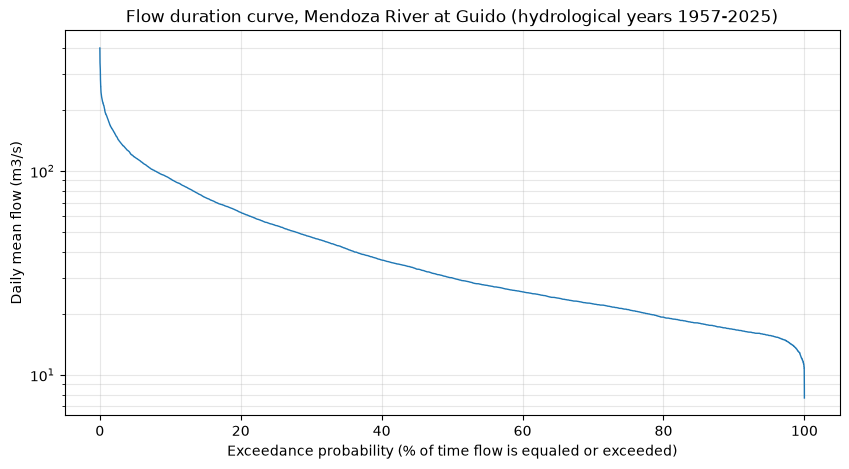

In [23]:
# Filter and keep only in q_hy the days from the 69 full years, to be consistent with D6:
q_hy = q[(hydro_year >= 1957) & (hydro_year <= 2025)]

# Sort in descending order and reset the index:
q_sorted = q_hy.sort_values(ascending=False).reset_index(drop=True) #drop=True replaces the dates for positions: 0,1,2,..

# Calculate the exceedance probability (Weibull formula).
exceedance = 100 * (q_sorted.index + 1) / (len(q_sorted) + 1) # M: is the position + 1, because Python starts counting at 0:

# Calculate the Qp values : quantiles
print("Qp values:")
for p in [10, 30, 40, 50, 90, 95]:
    print(f"Q{p}: {q_hy.quantile(1 - p/100):.1f} m3/s") # we use (1 - p/100) because “quantile” returns the value at the x% percentile below, and we want the value above x% 

Q10 = q_hy.quantile(1 - 10/100)
Q90 = q_hy.quantile(1 -90/100)
print("Q10 is ", round(Q10/Q90,1),  "times as big as Q90")

# Plot exceedance probability (x-axis, %) against discharge (y-axis, m³/s)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(exceedance, q_sorted, linewidth=1)   # x: % of time exceeded, y: flow
ax.set_yscale("log")                         # log scale: low winter flows and summer peaks both visible
ax.set_xlabel("Exceedance probability (% of time flow is equaled or exceeded)")
ax.set_ylabel("Daily mean flow (m3/s)")
ax.set_title("Flow duration curve, Mendoza River at Guido (hydrological years 1957-2025)")
ax.grid(True, which="both", alpha=0.3)   
fig.savefig("../docs/figures/flow_duration_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation
1) The Q10/Q90 ratio of ≈ 5.5 indicates that Q10 is approximately 5.5 times greater than Q90: The Q10 value corresponds to the snowmelt season (which generates high flows), while the Q90 value corresponds to the winter season, characterized by a winter base flow; for this reason, the 5.5x ratio is, above all, seasonal.
Furthermore, it is worth noting that the FDC does not show the chronological sequence of flows (Searcy, 1959), since the values have been rearranged from highest to lowest. In other words, the probability of exceedance and the quantiles are derived from the FDC, while the persistence and sequence of dry years continue to be derived from the analysis presented in Section 1.6.

2) The candidate design flow rate falls between Q30 and Q40: approximately 110 to 146 days per year at full load with excess flow spilled.

3) Q90 is equivalent to 35% of the design flow rate (Q90/Q30) with one power-generating turbine, and 70% with two (Q90 / (Q30/2)). Considering that the minimum technical flow rate for a Francis-type turbine is approximately 50% of the nominal flow rate according to the National Technical University of Athens [https://www.itia.ntua.gr/el/getfile/2050/7/documents/06_SmallHydroSupplementary.pdf], the option of using two Francis-type turbines is attractive in terms of remaining above that minimum technical flow rate.
However, two units imply higher CAPEX and O&M than one unit of the same total capacity; whether the extra winter energy pays for it is to be verified once energy and CAPEX are modeled.

4) Another important parameter when discussing hydroelectric turbines is the head, which, in the case of a Francis turbine, ranges from 25 to 350 meters according to Tsuanyo, D., Amougou, B., Aziz, A. et al.  [https://jrenewables.springeropen.com/articles/10.1186/s40807-023-00072-1/tables/2] (The parameters of head, ecological flow, and costs have yet to be defined).

## 1.8 Re-determining the design flows considering ecological flow

To determine the true turbination flow, the concept of ecological flow must be considered, which is defined as the minimum flow required in the river channel to sustain the ecosystem downstream of the project. Therefore, we perform the following calculation: Turbination flow = River flow – Ecological flow. 
Since no studies were found on the specific biology of the study area, nor were any local regulations found that establish an exact numerical value, we will use the method proposed by Tennant (1975) [https://files.dep.state.pa.us/Water/BSDW/Public_Water_Supply_Permits/TennantMethodPaper_1975.pdf]. The method states that the ecological flow is calculated as 10% of the average flow of the entire data series (AAF). To develop this method, Tennant uses stations in the Northern Hemisphere: April through September is their peak season. In the case study (and as noted earlier), the peak season is October through March, so if we use seasonal values, we will need to reverse the periods.
With the ecological flow determined (4.4 m³/s), the series of previous flows is corrected by subtracting the ecological flow, yielding q_available. 
Using q_available, we can recalculate the quantiles (Q10, Q30, Q40, Q50, Q90, Q95). 
Furthermore, it is crucial to note that the data in q_available will be used, since this represents the actual flow rate that can be utilized by the turbine. Otherwise, if the design is based on the river’s flow duration curve (FDC), we would be overestimating the flow rate that actually reaches the turbine: the plant would have idle capacity, and the calculated energy output would be inflated. 


### Key Actions Performed:
* **Determine the AAF:** The AAF is calculated as the average of all data points in the q_hy series.
* **Determine the ecological flow rate:** The ecological flow is defined as 10% of the AAF.
* **Determine the turbineable flow rate:** Using the ecological flow and the q_hy values, the available flow for power generation is determined: Qavailable = Qriver - Qecological.
* **Calculate the quantiles:** Just as in 1.7, the quantiles are calculated.


In [24]:
q_hy_average = q_hy.mean() #Determine the AAF as the average of all the average daily flow
print('Annual Average Flow (AAF): ',q_hy_average.round(2))

q_ec = q_hy_average * 0.1 #Ecological flow as 10% of AAF
print("10% of AAF: ",q_ec.round(2))

q_available = (q_hy - q_ec).clip(lower=0) # For each day, calculate the available flow : turbinable flow = river flow − ecological flow

print("Qp values with the available flow: ")
for p in [10, 30, 40, 50, 90, 95]:
    print(f"Q{p}: {q_available.quantile(1 - p/100):.1f} m3/s")

q_design = q_available.quantile(1 - 30/100)
print("Design flow (Q30): ",q_design.round(2))

quantity_cond1 =0 
quantity_cond2 =0 
quantity_cond3 =0 
quantity_cond4 =0 

for flow in q_available:
    if flow >= (q_design) :
        quantity_cond1 = quantity_cond1 + 1 
    elif flow >= (q_design/2) and flow < (q_design):
        quantity_cond2 = quantity_cond2 + 1
    elif flow >= (q_design/4) and flow < (q_design/2):
        quantity_cond3 = quantity_cond3 + 1
    else:
        quantity_cond4 = quantity_cond4 + 1
print()
total_available_days = quantity_cond1+quantity_cond2+quantity_cond3+quantity_cond4
print("Total quantity of days with available flow rate: ", total_available_days)
print("Percentage of days with Q ≥ design: ", round(quantity_cond1/total_available_days *100,1), "%")
print("Percentage of days with design/2 ≤ Q <design: ", round(quantity_cond2/total_available_days *100,1), "%")
print("Percentage of days with design/4 ≤ Q < design/2: ", round(quantity_cond3/total_available_days *100,1), "%")
print("Percentage of days with Q < design/4: ", round(quantity_cond4/total_available_days *100,1), "%")
print()
print("Days in Q ≥ design: ", quantity_cond1)
print("Days in design/2 ≤ Q < design: ", quantity_cond2)
print("Days in design/4 ≤ Q < design/2: ", quantity_cond3)
print("Days in Q < design/4: ", quantity_cond4)
print()
print("Days that Q ≥ design, in a year: ", round(365*(quantity_cond1/total_available_days),0))
print("Days that design/2 ≤ Q < design, in a year: ", round(365*(quantity_cond2/total_available_days),0))
print("Days that design/4 ≤ Q < design/2, in a year: ", round(365*(quantity_cond3/total_available_days),0))
print("Days that Q < design/4, in a year: ", round(365*(quantity_cond4/total_available_days),0))


print("--------------------------ANALYSIS FOR DRY YEARS: --------------------------")

hy_available = q_available.index.year + (q_available.index.month >= 10)
q_available_dry = q_available[hy_available.isin(dry_years_hy.index)]

quantity_dry_cond1 = 0
quantity_dry_cond2 = 0
quantity_dry_cond3 = 0
quantity_dry_cond4 = 0

for flow in q_available_dry:
    if flow >= (q_design) :
        quantity_dry_cond1 = quantity_dry_cond1 + 1 
    elif flow >= (q_design/2) and flow < (q_design):
        quantity_dry_cond2 = quantity_dry_cond2 + 1
    elif flow >= (q_design/4) and flow < (q_design/2):
        quantity_dry_cond3 = quantity_dry_cond3 + 1
    else:
        quantity_dry_cond4 = quantity_dry_cond4 + 1
print()
total_available_days_dry = quantity_dry_cond1 + quantity_dry_cond2 + quantity_dry_cond3 + quantity_dry_cond4
print("Total quantity of days with available flow rate: ", total_available_days_dry)
print("Percentage of days with Q ≥ design: ", round(quantity_dry_cond1/total_available_days_dry *100,1), "%")
print("Percentage of days with design/2 ≤ Q < design: ", round(quantity_dry_cond2/total_available_days_dry *100,1), "%")
print("Percentage of days with design/4 ≤ Q < design/2: ", round(quantity_dry_cond3/total_available_days_dry *100,1), "%")
print("Percentage of days with Q < design/4: ", round(quantity_dry_cond4/total_available_days_dry *100,1), "%")
print()
print("Days in Q ≥ design: ", quantity_dry_cond1)
print("Days in design/2 ≤ Q < design: ", quantity_dry_cond2)
print("Days in design/4 ≤ Q < design/2: ", quantity_dry_cond3)
print("Days in Q < design/4: ", quantity_dry_cond4)
print()
print("Days that Q ≥ design, in a year: ", round(365*(quantity_dry_cond1/total_available_days_dry),0))
print("Days that design/2 ≤ Q < design, in a year: ", round(365*(quantity_dry_cond2/total_available_days_dry),0))
print("Days that design/4 ≤ Q < design/2, in a year: ", round(365*(quantity_dry_cond3/total_available_days_dry),0))
print("Days that Q < design/4, in a year: ", round(365*(quantity_dry_cond4/total_available_days_dry),0))



Annual Average Flow (AAF):  44.0
10% of AAF:  4.4
Qp values with the available flow: 
Q10: 87.1 m3/s
Q30: 43.0 m3/s
Q40: 32.2 m3/s
Q50: 25.5 m3/s
Q90: 12.3 m3/s
Q95: 11.2 m3/s
Design flow (Q30):  43.01

Total quantity of days with available flow rate:  25202
Percentage of days with Q ≥ design:  30.0 %
Percentage of days with design/2 ≤ Q <design:  28.9 %
Percentage of days with design/4 ≤ Q < design/2:  37.5 %
Percentage of days with Q < design/4:  3.5 %

Days in Q ≥ design:  7561
Days in design/2 ≤ Q < design:  7291
Days in design/4 ≤ Q < design/2:  9458
Days in Q < design/4:  892

Days that Q ≥ design, in a year:  110.0
Days that design/2 ≤ Q < design, in a year:  106.0
Days that design/4 ≤ Q < design/2, in a year:  137.0
Days that Q < design/4, in a year:  13.0
--------------------------ANALYSIS FOR DRY YEARS: --------------------------

Total quantity of days with available flow rate:  12418
Percentage of days with Q ≥ design:  20.2 %
Percentage of days with design/2 ≤ Q < design: 

### Interpretation

The most important results are:
 - Average annual flow: 44.0 m³/s.
 - Ecological flow: 4.4 m³/s.
 - Q30 of q_available: 43.0 m³/s. This is the design flow, consisting of 2 units of 21.5 m³/s.
 - Operating thresholds: 
   - design = 43.0 m³/s.
   - design/2 = 21.5 m³/s.
   - design/4 = 10.75 m³/s. 
The last value is 50% of one unit, the technical minimum for the Francis turbine according to NTUA [https://www.itia.ntua.gr/el/getfile/2050/7/documents/06_SmallHydroSupplementary.pdf].


| Category | Complete period | Dry years |
| :--- | :---: | ---: |
| Q ≥ design | 30% | 20.2% |
| design/2 ≤ Q < design | 28.9% | 23.8% |
| design/4 ≤ Q < design/2 | 37.5% | 48.9% |
| Q < design/4 | 3.5% | 7.1% |

| Category | Complete period [days/year] | Dry years [days/year] |
| :--- | :---: | ---: |
| Q ≥ design | 110 | 74 |
| design/2 ≤ Q < design | 106 | 87 |
| design/4 ≤ Q < design/2 | 137 | 179 |
| Q < design/4 | 13 | 26 |

There is a difference between the changes in percentage points and the relative change, this is because the relative change is measured against the starting value: a small starting value (3.5%) that doubles:
 - Largest absolute change: The one-unit segment rose by +11.4 percentage points, a relative increase of ~30%.
 - Largest relative change: The below-minimum segment (Q < design/4) rises by +3.6 points, but doubles (+100%). 

Hypothesis regarding energy:
 - The table counts days (not energy): A day at full capacity generates approximately twice as much as a day with a single unit running at full capacity.
 - The biggest blow to energy production during dry years is the loss of ~36 days of full-load operation per year.
 - The entire distribution of daily flows shifts downward.
 - That is why the P90 energy is expected to be well below the P50. This will be confirmed (or rejected) when the annual energy is calculated year by year.

Limitations:
- The results depend on:
    - D5: dry years defined by a relative criterion, below the median.
    - D7: 10% ecological flow according to Tennant.
    - The 50% minimum technical flow of Francis turbines (NTUA).
- The head has not yet been defined, so the type of turbine has not been confirmed either.

## 1.9 Head, installed capacity and turbine type

The next step is to calculate the head, determine the installed power, and use this information to select a turbine type for the plant.
First, let’s review the power equation: P = ρ · g · Q · H_n · η. Where:
- ρ = 1000 kg/m³, the density of water.
- g = 9.81 m/s².
- Q = turbine flow rate (m³/s).
- H_n = net head (m).
- η = efficiency.
This gives us power in watts.
It is important to note that there are two types of head: gross and net. The former is the direct difference in elevation between the intake and the powerhouse, while the latter is the difference in elevation that also accounts for hydraulic losses in the canal and the fittings. 
For this particular analysis, since it involves a run-of-river hydroelectric plant, the river is not dammed; instead, a canal with a gentler slope than the river is constructed upstream, so that when the water reaches the powerhouse, the canal is above the natural riverbed (thus creating the elevation difference).
Since the exact topography of the site is not considered in this project, we will assume a reference power of 10 MW (10e6 watts) and calculate the head required to achieve this power [To be verified in the future].
Furthermore, the USBR [https://www.usbr.gov/power/edu/pamphlet.pdf] states that for modern hydroelectric power plants, efficiency is around 90%; however, for small plants that operate at partial load for much of the time (as in this case study), it is advisable to use a slightly lower value.
Next, the percentage of days below the minimum technical flow threshold is determined for each configuration, both for the complete time series (all years) and for the series consisting only of dry years.

### Key Actions Performed:
* **Determining Head Using the Power Equation:** as explained earlier, P = ρ · g · Q · H_n · η
* **Determining the power generation thresholds for each configuration:** Francis turbines are considered to have a threshold of 50% of the design flow rate, while Kaplan turbines have a threshold of 15% of the design flow rate [ESHA (table 3-2, p. 62, https://energycommunityplatform.eu/wp-content/uploads/2022/06/)]
* **Determining the Percentage of Days Below the Threshold:** For both the complete series of days and the series of days from dry years only, the percentage of days that fall below the efficiency threshold is calculated for the three configurations. This allows us to see how many days in the series the hydroelectric plant generates negligible amounts of energy.



In [25]:
# Defining values for equation: P = ρ · g · Q · H_n · η // Q=q_design
P_installed = 10e6
eta = 0.88
rho = 1000 
g = 9.81

H_n = P_installed/(rho*g*q_design*eta)
print("Head (with P=10MW ; ρ = 1000 kg/m3 ; η=0.88 ; g=9.81 m/s2 ):  ", round(H_n,1))
q_min_A = q_design/2 * 0.5
q_min_B = q_design * 0.15
q_min_C = q_design/2 * 0.15
print()
print("ENERGY GENERATION THRESHOLD FOR EACH CONFIGURATION")
print(f"Config. A: 2x Francis ({round(q_design/2,1)} m3/s each): ",round(q_min_A,1))
print(f"Config. B: 1x Kaplan ({round(q_design,1)} m3/s each): ",round(q_min_B,1))
print(f"Config. C: 2x Kaplan ({round(q_design/2,1)} m3/s each): ",round(q_min_C,1))
print()

# Analisis for total years [wet and dry years]

q_min_A_count=0
q_min_B_count=0
q_min_C_count=0

for flow in q_available:
    if flow < q_min_A:
        q_min_A_count = q_min_A_count + 1

for flow in q_available:
    if flow < q_min_B:
        q_min_B_count = q_min_B_count + 1

for flow in q_available:
    if flow < q_min_C:
        q_min_C_count = q_min_C_count + 1

# Analisis for dry years only

q_min_A_count_dry=0
q_min_B_count_dry=0
q_min_C_count_dry=0

for flow in q_available_dry:
    if flow < q_min_A:
        q_min_A_count_dry = q_min_A_count_dry + 1

for flow in q_available_dry:
    if flow < q_min_B:
        q_min_B_count_dry = q_min_B_count_dry + 1

for flow in q_available_dry:
    if flow < q_min_C:
        q_min_C_count_dry = q_min_C_count_dry + 1

# Display results

print("FOR TOTAL DAYS [WET AND DRY YEARS]")
print(f"Config. A: 2x Francis ({round(q_design/2,1)} m3/s each), days below min. threshold: ", round(q_min_A_count/len(q_available)*100,1), "%")
print(f"Config. B: 1x Kaplan ({round(q_design,1)} m3/s each), days below min. threshold: ", round(q_min_B_count/len(q_available)*100,1), "%")
print(f"Config. C: 2x Kaplan ({round(q_design/2,1)} m3/s each), days below min. threshold: ", round(q_min_C_count/len(q_available)*100,1), "%")
print()
print("FOR DRY YEARS ONLY")
print(f"Config. A: 2x Francis ({round(q_design/2,1)} m3/s each), days below min. threshold: ", round(q_min_A_count_dry/len(q_available_dry)*100,1), "%")
print(f"Config. B: 1x Kaplan ({round(q_design,1)} m3/s each), days below min. threshold: ", round(q_min_B_count_dry/len(q_available_dry)*100,1), "%")
print(f"Config. C: 2x Kaplan ({round(q_design/2,1)} m3/s each), days below min. threshold: ", round(q_min_C_count_dry/len(q_available_dry)*100,1), "%")
print()


Head (with P=10MW ; ρ = 1000 kg/m3 ; η=0.88 ; g=9.81 m/s2 ):   26.9

ENERGY GENERATION THRESHOLD FOR EACH CONFIGURATION
Config. A: 2x Francis (21.5 m3/s each):  10.8
Config. B: 1x Kaplan (43.0 m3/s each):  6.5
Config. C: 2x Kaplan (21.5 m3/s each):  3.2

FOR TOTAL DAYS [WET AND DRY YEARS]
Config. A: 2x Francis (21.5 m3/s each), days below min. threshold:  3.5 %
Config. B: 1x Kaplan (43.0 m3/s each), days below min. threshold:  0.1 %
Config. C: 2x Kaplan (21.5 m3/s each), days below min. threshold:  0.0 %

FOR DRY YEARS ONLY
Config. A: 2x Francis (21.5 m3/s each), days below min. threshold:  7.1 %
Config. B: 1x Kaplan (43.0 m3/s each), days below min. threshold:  0.1 %
Config. C: 2x Kaplan (21.5 m3/s each), days below min. threshold:  0.0 %



### Interpretation
1)  In summary, the days that fall below the power generation threshold are:

| Config | Complete period | Dry years |
| :--- | :---: | ---: |
| A (2×Francis) | 3.5% | 7.1% |
| B (1×Kaplan) | 0.05% | 0.1% |
| C (2×Kaplan) | 0.0% | 0.0% |

2) Based on these results, the decision was made to choose Configuration B for the following reasons:
 - Config. B allows for operation with just one turbine designed for 43 m³/s instead of two, which simplifies operations.
 - Regarding lost production days: In practice, the days for configuration B are the same as for C. That is, 13 days versus 0 over 69 years. Therefore, B loses practically the same as C and much less than A.
 - Limitation (1): The aforementioned equality between B and C results from assuming that η is constant. In reality, a single Kaplan turbine with a flow rate of 43 m3/s spends much of the winter operating between 15% and 50% of its design capacity, where efficiency is lower. The model does not account for this loss, so it overestimates B.
 - Limitation (2): The operational advantage of being able to repair one turbine while the other is running is completely lost.

3) Configuration A is not completely ruled out; rather, it is retained as a sensitivity scenario for Section 1.11.

## 1.10 Daily power and energy

In this section, we will calculate power and energy, and we will also perform some checks to compare them with the previous sections: 1.8 and 1.9.
First, a new series called q_turbined is generated, which contains the flow rates that the turbine will actually use to generate power. For this purpose, the maximum value will be q_design (the turbine’s design flow rate), and all flow rates below the technical minimum will be replaced with zero (the turbine is considered to be shut down).
With this, the power is calculated using the formula we’ve already seen: [P = ρ · g · Q · H_n · η], and the daily energy is calculated by multiplying the power by 24 [ESHA, section 3.6, https://energycommunityplatform.eu/wp-content/uploads/2022/06/]. For the energy calculation, the flow rate is assumed to be constant throughout the day [simplification]. 
This allows us to verify the following:
 -  The maximum power value in the power_mw series must be 10 MW. This does not prove anything new but demonstrates that the code is consistent (that the same H_n, η, and q_design were used in both sections).
 - The percentage of days with power equal to the maximum is 30%. This matches the percentage value obtained in Section 1.8 [“Percentage of days with Q ≥ design”].
 - The number of days with zero power corresponds to the number of days when the flow rate reaching the turbine is less than the minimum flow rate required for it to operate. In both cases, the value is 13 days, confirming the consistency of these results between Sections 1.9 and 1.10.

### Key Actions Performed:
* **Create and tune q_turbined:**  As explained earlier, the flow rate values in q_turbined must be between q_min_B and q_design.
* **Create the power_mw and energy_mwh series:**  The power series is calculated using the corresponding formula, and the energy series is derived from the power series by multiplying its values by 24. The power values are divided by 1e6 to convert them to MW. Energy, on the other hand, is measured in MWh/day.
* **Final verifications:**  As explained above, the necessary checks are performed




In [26]:
# Define and tune q_turbined: 2 conditions: clip it with an upper value = q_design. And make =0 the q values that are less than q_min_B (minimum operating flow)
q_turbined = q_available.clip(upper = q_design)
q_turbined = q_turbined.where(q_turbined >= q_min_B,0)

# Define power_mw and energy_mwh with the already tuned q_turbined
power_mw = (rho * g * q_turbined * H_n * eta)/(1e6)   # P = ρ · g · Q · H_n · η 
energy_mwh = power_mw * 24
print()
# Print results: Use describe and not print
print("POWER VALUES [MW]: ")
print(power_mw.describe())
print()
print("ENERGY VALUES VALUES [MWh/day]: ")
print(energy_mwh.describe())
print()
# Print the control values [Verifications]
top_days = (q_turbined == q_design).sum()
perc_days = (q_turbined == q_design).mean() * 100
no_pow_days = (q_turbined == 0).sum()
print("VERIFICATIONS: ")
print("The max value in the power series is: ", max(power_mw), "MW") #Verification: Check that the max power is the design power P_installed
print("Number of days with power equal to the maximum: ", top_days) # This should be equal to the value in 1.8
print("Percentage of days with power equal to the maximum: ", round(perc_days,1), "%") # This should be equal to the value in 1.8
print("Number of days with power = 0: ", no_pow_days) # This should be equal to the value in 1.9




POWER VALUES [MW]: 
count    25202.000000
mean         6.472065
std          2.867728
min          0.000000
25%          3.836600
50%          5.929277
75%         10.000000
max         10.000000
Name: q_m3s, dtype: float64

ENERGY VALUES VALUES [MWh/day]: 
count    25202.000000
mean       155.329570
std         68.825470
min          0.000000
25%         92.078395
50%        142.302655
75%        240.000000
max        240.000000
Name: q_m3s, dtype: float64

VERIFICATIONS: 
The max value in the power series is:  10.0 MW
Number of days with power equal to the maximum:  7561
Percentage of days with power equal to the maximum:  30.0 %
Number of days with power = 0:  13


## 1.11 Annual energy, P50, P90 and plant factor

In this section we add the daily energy of each hydrological year (Oct-Sep, D6) to get one value of annual energy per year (69 values, 1957-2025). With these 69 values we calculate the P50, the P90 and the plant factor.

**P50 and P90 (exceedance probability).** They are levels of annual energy with a probability of being exceeded:
- P50: the annual energy that is exceeded in 50% of the years. It is the median, the "typical" year.
- P90: the annual energy that is exceeded in 90% of the years. Only 1 year in 10 produces less than this.

Banks ask for both values to judge if a project can pay its debt. The P90 is the conservative value used to size the debt (D1). Source: Penn State EME 810, 8.4 Exceedance Probabilities: P50, P75, P90 [https://courses.ems.psu.edu/eme810/node/630].

This is the same exceedance logic as the flow duration curve (1.7), but applied to the energy of each year instead of the flow of each day. For this reason the P90 is the 10th percentile: `quantile(0.10)`.

**Plant factor (capacity factor).** It is the energy the plant really produces in a period, divided by the energy it would produce running at full power during the whole period. For one year:

Plant factor = annual energy / (10 MW × 8,760 h) = annual energy / 87.6 GWh

Source: EIA Glossary, "Capacity factor" [https://www.eia.gov/tools/glossary/index.php?id=C].

### Key Actions Performed:
* **Annual energy:** daily energy (MWh) is added by hydrological year and converted to GWh.
* **Check:** there must be 69 complete hydrological years (1957-2025).
* **P50 and P90:** calculated as empirical percentiles of the 69 annual values (pandas `quantile`, linear interpolation).
* **Plant factor:** calculated for every year, for the P50 and for the P90. Check: the percentile of the plant factor series must match the plant factor of the energy percentile.
* **Years below the P90:** listed and compared with the dry years and dry streaks of section 1.6.

YEAR QUANTITY: 69 (first: 1957, last: 2025)
ANNUAL AVERAGE: 56.7 GWh
P50 VALUE: 57.1 GWh
P90 VALUE: 45.0 GWh
P90/P50 = 0.79

CAPACITY FACTOR FOR P50: 65.1%
CAPACITY FACTOR FOR P90: 51.4%
Check cf(P50): 65.1% | Check cf(P90): 51.4%

YEARS BELOW P90: {1965: 43.7, 1969: 34.7, 1971: 38.4, 1997: 41.5, 2011: 42.5, 2020: 42.0, 2022: 41.0}
Of those, dry years: [1965, 1969, 1971, 1997, 2011, 2020, 2022]


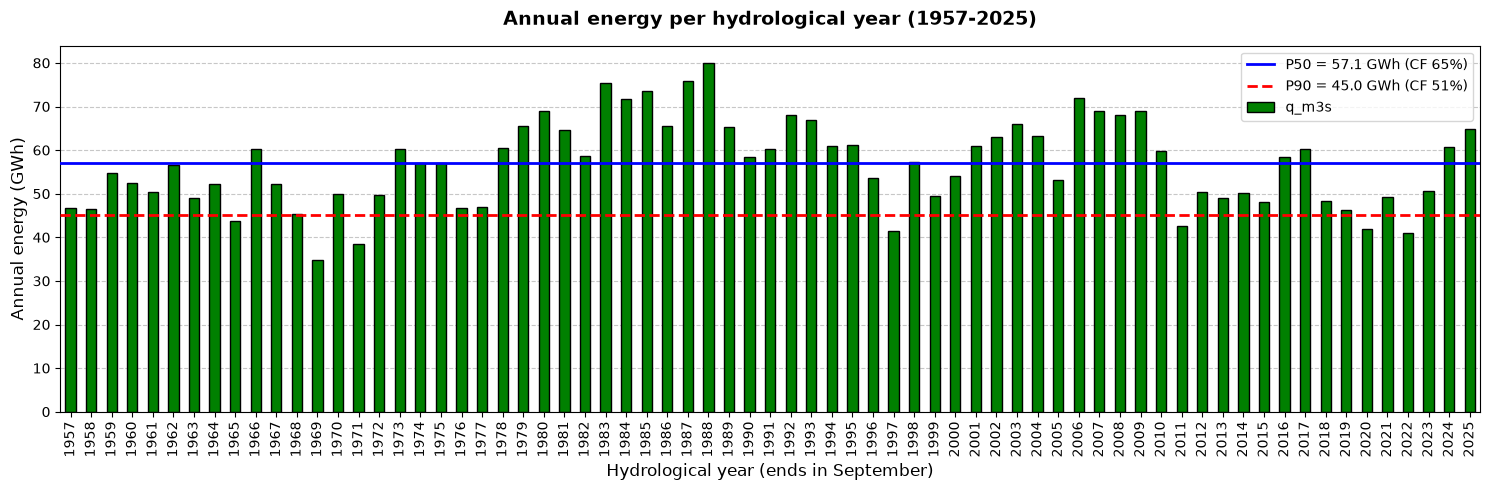

In [ ]:
# Annual energy per HYDROLOGICAL year (Oct-Sep, D6), in GWh
hy_energy = energy_mwh.index.year + (energy_mwh.index.month >= 10)
e_annual_gwh = energy_mwh.groupby(hy_energy).sum() / 1000   # MWh -> GWh

# Check: must be 69 complete hydrological years (1957-2025)
print(f"YEAR QUANTITY: {len(e_annual_gwh)} (first: {e_annual_gwh.index.min()}, last: {e_annual_gwh.index.max()})")

# P50 and P90: energy exceeded in 50% / 90% of years -> 50th / 10th percentile
P50_gwh = e_annual_gwh.quantile(0.50)
P90_gwh = e_annual_gwh.quantile(0.10)
print(f"ANNUAL AVERAGE: {e_annual_gwh.mean():.1f} GWh")
print(f"P50 VALUE: {P50_gwh:.1f} GWh")
print(f"P90 VALUE: {P90_gwh:.1f} GWh")
print(f"P90/P50 = {P90_gwh / P50_gwh:.2f}")
print()

# Capacity factor = actual energy / energy at full power all year
P_installed_mw = P_installed / 1e6
e_max_gwh = P_installed_mw * 8760 / 1000          # max theoretical annual energy (GWh)
cf_annual = e_annual_gwh / e_max_gwh              # one value per year
cf_P50 = P50_gwh / e_max_gwh
cf_P90 = P90_gwh / e_max_gwh
print(f"CAPACITY FACTOR FOR P50: {cf_P50:.1%}")
print(f"CAPACITY FACTOR FOR P90: {cf_P90:.1%}")

# Check: percentile of the CF series must match CF of the energy percentile
print(f"Check cf(P50): {cf_annual.quantile(0.50):.1%} | Check cf(P90): {cf_annual.quantile(0.10):.1%}")
print()

# Years below P90, and how many of them are dry years (D5/D6)
years_below_p90 = e_annual_gwh[e_annual_gwh < P90_gwh]
print("YEARS BELOW P90:", years_below_p90.round(1).to_dict())
print("Of those, dry years:", [y for y in years_below_p90.index if y in dry_years_hy.index])

# Plot: annual energy (GWh) with P50 and P90 lines
fig, ax = plt.subplots(figsize=(15, 5))
e_annual_gwh.plot(kind="bar", color="green", edgecolor="black", zorder=2, ax=ax,label="Annual energy" )
ax.axhline(P50_gwh, color="blue", linestyle="-", linewidth=2, zorder=3,
           label=f"P50 = {P50_gwh:.1f} GWh (CF {cf_P50:.0%})")
ax.axhline(P90_gwh, color="red", linestyle="--", linewidth=2, zorder=3,
           label=f"P90 = {P90_gwh:.1f} GWh (CF {cf_P90:.0%})")
ax.set_title("Annual energy per hydrological year (1957-2025)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Hydrological year (ends in September)", fontsize=12)
ax.set_ylabel("Annual energy (GWh)", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=1)
ax.legend()
plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig("../docs/figures/annual_energy.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

**1) Main results**

| Value | Annual energy (GWh) | Plant factor |
| :--- | :---: | :---: |
| Mean | 56.7 | 64.8% |
| P50 | 57.1 | 65.1% |
| P90 | 45.0 | 51.4% |
| P90 / P50 | 0.79 | |

**2) What these values mean**
- The P50 is the median, the typical year. Here it is very close to the mean (57.1 vs 56.7 GWh), but they are not the same concept.
- The P90 is not the worst case. It is a bad year that is exceeded 9 years out of 10. The worst year on record is 1969, with 34.7 GWh, only 61% of the P50. Seven years fall below the P90.
- P90 / P50 = 0.79: in a P90 year the plant produces 21% less energy than in a typical year. Because the debt is sized on the P90 (D1), the bank lends against 21% less energy than a typical year. The closer this ratio is to 1, the more debt the project can carry.
- This ratio measures the variability between years (interannual). It is a different thing from Q10/Q90 = 5.5 in section 1.7, which measures the variability within the year (seasonal, snowmelt). For the debt, the interannual variability is the one that matters.

**3) Years below the P90 and dry streaks**

| Year | Annual energy (GWh) | Dry year (1.6)? | Inside a dry streak (1.6)? |
| :--- | :---: | :---: | :--- |
| 1965 | 43.7 | Yes | No (isolated dry year) |
| 1969 | 34.7 | Yes | Yes (1967-1972) |
| 1971 | 38.4 | Yes | Yes (1967-1972) |
| 1997 | 41.5 | Yes | Yes (1996-1997) |
| 2011 | 42.5 | Yes | Yes (2011-2015) |
| 2020 | 42.0 | Yes | Yes (2018-2023) |
| 2022 | 41.0 | Yes | Yes (2018-2023) |

- All 7 years below the P90 are dry years, and 6 of them are inside dry streaks.
- Note: it is expected by construction that only about 7 of 69 years fall below the P90 (it is the 10th percentile), while about 34 of 69 years are dry (the dry-year threshold is the median). The comparison of these two counts is not a finding. The finding is where the bad years are.

**4) Hypothesis (to be tested in the financial stage)**
- The annual P90 treats every year as independent. The data show that bad years come together, inside dry streaks.
- For the debt this is worse than one isolated bad year: several years in a row with lower income and the same debt payment. This is hypothesis H1, and it will be measured in the financial model.

**5) Limitations**
- P50 and P90 are empirical percentiles of only 69 values. The P90 depends on a few low years.
- The P90 is a one-year value. It does not describe the risk of several bad years in a row.
- All results depend on previous assumptions: D4 (interpolation), D7 (ecological flow 10%), D8 (constant η = 0.88, 1 Kaplan unit, head 26.9 m) and the daily-flow simplification of section 1.10.

## 1.12 Sensitivity Analysis
The next step is to perform a sensitivity analysis:
 - Sensitivity analysis involves changing one assumption at a time, performing the corresponding calculations, and measuring how much the values of interest change: In this case study, these values are P50 and P90, which are compared to the base case (1.11).
 - Sensitivity analysis is used to identify which assumptions are material, that is, which ones change a decision. In this way, we can better understand the actual behavior of the phenomenon under study.
 - Source: CFI, “What is Sensitivity Analysis?". https://corporatefinanceinstitute.com/resources/financial-modeling/what-is-sensitivity-analysis/

With this in mind, we must determine which parameters will remain constant and which ones will be varied. The modeling criteria are as follow:
 - Fixed parameters: design flow rate 43.0 m3/s, head 26.9 m, η = 0.88, and maximum power 10 MW. The fixed parameters are those that remain constant after construction: design flow rate, head, η, and maximum power
 - Parameters to be subjected to sensitivity analysis (variables): These are those associated with what happens after construction, or those that are still uncertain (regulation, technology, data).
 - In other words, we focus on the question the bank might ask: “What if, once it’s built, [something] changes?” This modeling of changes to the assumption is what sensitivity analysis seeks to measure.

Therefore, the scenarios proposed for this analysis are:
 - Ecological flow: With values of 20% and 30% (D7): external regulatory risk.
 - Consider Configuration A: 2×Francis (D8): This scenario represents a design alternative. It is worth noting that this is a design alternative, not a potential future risk.
 - Scenario without interpolated years (D4): This corresponds to a data quality check. In this scenario, the five hydrological years with filled-in days [interpolated in previous sections] are excluded: 1962, 1970, 1976, 1985, and 2023.

Methodology for Conducting a Sensitivity Analysis:
 - In this case, we chose to use a Python function, since it allows us to perform the same calculation with different parameters without having to copy the same blocks of code for different scenarios. We then define the function `compute_annual_energy(eco_fraction, min_tech_fraction, n_units)`
 - The `compute_annual_energy` function also contains default values, which correspond to the base case already developed. `compute_annual_energy(eco_fraction=0.10, min_tech_fraction=0.15, n_units=1)`
 - The goal is for this function to calculate and return the annual energy [using the selected parameters for each case]. The “output” of this function is used to calculate the P50 and P90 values for each scenario.
 - Variable scope: Variables assigned inside a function are local. This means that variables assigned values within a function retain those values only within that function and do not extend to other code blocks. 
 - Source: Python docs, 4.8. https://docs.python.org/3/tutorial/controlflow.html#defining-functions

Validation of D4: In Decision D4, 103 days were filled in using linear interpolation, and it remained to be determined whether this would change the result. In this section, the test is conducted by recalculating P50 and P90 while excluding hydrological years that have at least one interpolated day. Subsequently, the P50 and P90 values are compared to the P50 and P90 values from the base case. This then leads to two possible scenarios: 
 - If the difference between P50 and P90 [of the series without interpolated years] and P50 and P90 [of the complete series, with interpolated days] is small, then it can be concluded that the interpolation decided upon in D4 does not deviate significantly from reality. In this scenario, the years with interpolated days are retained, and the analysis proceeds. 
 - If the difference between P50 and P90 [of the series without filled-in years] and P50 and P90 [of the complete series, with interpolated days] is large, it can be concluded that the interpolation method chosen in D4 deviates from reality, resulting in unusable results. In this scenario, The interpolation method should be reviewed.

Using the results returned by the `compute_annual_energy` function, the following checks are performed:
 - With the default values, the function returns the base case: P50 = 57.1 and P90 = 45.0.
 - The ‘assert’ command is used to check the maximum power of 10 MW in each scenario: It verifies that the maximum amount of power generated is 10 MW. If the maximum power differs from 10 MW, the function returns an error (since the plant is exactly the same, and the ‘head’ was determined based on a fixed power of 10 MW; the fact that the function returns a higher value indicates an inconsistency in the code).
 - In addition, for each scenario [Eco 20%, Eco 30%, Config. A, No interpolated years], the variation ‘Δ’ relative to the base case is determined. Logically, the column showing the variation in P50 and P90 relative to the base case is Δ = 0 (since it is the reference scenario).
 - It was found that 5 of those years contain days for which no measurements were taken, which means that the values for those days were interpolated: If we exclude those years, we are left with 64 years, which is still a large number of years for conducting the case study. 
 - In addition, the physical limit on energy generation is 87.6 GWh. This is the theoretical maximum amount of energy that can be generated in a year, and it occurs when the turbine receives its design flow rate constantly.

### Key Actions Performed:
* **Create a function:** `compute_annual_energy`
* **D4 Validation:** The validation of D4 is performed using the logic explained above.
* **Definition of scenarios:** Eco 20%, Eco 30%, Config. A, No interpolated years
* **Results table:** A table of the most important results for the upcoming phases is generated.

In [28]:
def compute_annual_energy(eco_fraction=0.10, min_tech_fraction=0.15, n_units=1):
    """Return annual energy (GWh) per hydrological year for one scenario.
    Design flow (q_design), head (H_n) and efficiency (eta) stay fixed."""

    # 1) Available flow: river flow minus ecological flow (eco_fraction x mean flow)  -> section 1.8

    q_ec = q_hy_average * eco_fraction
    q_available = (q_hy - q_ec).clip(lower=0) 

    # 2) Turbined flow: cap at q_design; zero below the minimum technical flow
    #    of ONE unit = min_tech_fraction x (q_design / n_units)                       -> section 1.10

    q_min_tech = min_tech_fraction * (q_design / n_units)
        # Re-tunning q_available to obtain q_turbined
    q_turbined = q_available.clip(upper = q_design)
    q_turbined = q_turbined.where(q_turbined >= q_min_tech,0)

    # 3) Daily energy (MWh) with P = rho*g*Q*H*eta, times 24                           -> section 1.10
        # Define power_mw and energy_mwh with the already tuned q_turbined
    power_mw = (rho * g * q_turbined * H_n * eta)/(1e6)   # P = ρ · g · Q · H_n · η 
    energy_mwh = power_mw * 24
        # Check that the power is still 10 MW: fixed parameter
    assert abs(power_mw.max() - 10) < 0.01, "Max power must stay at 10 MW (same plant)" 

    # 4) Sum by hydrological year, divide by 1000 -> GWh                                -> section 1.11
    hy_energy = energy_mwh.index.year + (energy_mwh.index.month >= 10)
    e_annual_gwh = energy_mwh.groupby(hy_energy).sum() / 1000   # MWh -> GWh

    return e_annual_gwh

# Generate the different scenarios: Base, eco=20%, eco=30%, config. A
e_base  = compute_annual_energy()
e_eco20 = compute_annual_energy(eco_fraction=0.20)
e_eco30 = compute_annual_energy(eco_fraction=0.30)
e_confA = compute_annual_energy(min_tech_fraction=0.50, n_units=2)

# For each scenario function output, calculate P50 and P90
for name, e in [("Base", e_base), ("Eco 20%", e_eco20), ("Eco 30%", e_eco30), ("Config A", e_confA)]:
    print(f"{name}: P50 = {e.quantile(0.50):.1f} GWh | P90 = {e.quantile(0.10):.1f} GWh")


# D4 validation: drop hydrological years that contain interpolated days

hy_all = q.index.year + (q.index.month >= 10)
filled_years = sorted(set(hy_all[filled.values]))

e_no_interp = e_base.drop(filled_years)          # same annual energy, without those 5 years

print(f"Years dropped: {filled_years} -> {len(e_no_interp)} years left")
for name, e in [("Base (69 years)", e_base), ("Without interpolated years", e_no_interp)]:
    print(f"{name}: P50 = {e.quantile(0.50):.1f} GWh | P90 = {e.quantile(0.10):.1f} GWh")

change_p50 = (e_no_interp.quantile(0.50) / e_base.quantile(0.50) - 1) * 100
change_p90 = (e_no_interp.quantile(0.10) / e_base.quantile(0.10) - 1) * 100
print(f"Change vs base: P50 {change_p50:+.1f}% | P90 {change_p90:+.1f}%")

# Create a Dataframe from a list
rows = []
for name, e in [("Base", e_base), ("Eco 20%", e_eco20), ("Eco 30%", e_eco30), ("Config A", e_confA), ("No interpolated years", e_no_interp)]:
    rows.append({"Scenario": name, "P50 (GWh)": e.quantile(0.50), "P90 (GWh)": e.quantile(0.1), "P90/P50": e.quantile(0.1)/e.quantile(0.50), "ΔP50 vs base (%)": ((e.quantile(0.50) / e_base.quantile(0.50) - 1) * 100).round(1), "ΔP90 vs base (%)":((e.quantile(0.1) / e_base.quantile(0.1) - 1) * 100).round(1), })
results = pd.DataFrame(rows).round(2)
display(results)

Base: P50 = 57.1 GWh | P90 = 45.0 GWh
Eco 20%: P50 = 50.9 GWh | P90 = 36.3 GWh
Eco 30%: P50 = 42.5 GWh | P90 = 26.6 GWh
Config A: P50 = 57.1 GWh | P90 = 42.7 GWh
Years dropped: [1962, 1970, 1976, 1985, 2023] -> 64 years left
Base (69 years): P50 = 57.1 GWh | P90 = 45.0 GWh
Without interpolated years: P50 = 57.8 GWh | P90 = 44.2 GWh
Change vs base: P50 +1.4% | P90 -1.8%


,Scenario,P50 (GWh),P90 (GWh),P90/P50,ΔP50 vs base (%),ΔP90 vs base (%)
0,Base,57.07,45.02,0.79,0.0,0.0
1,Eco 20%,50.92,36.30,0.71,-10.8,-19.4
2,Eco 30%,42.53,26.55,0.62,-25.5,-41.0
3,Config A,57.07,42.71,0.75,0.0,-5.1
4,No interpolated years,57.84,44.19,0.76,1.4,-1.8


### Interpretation

**1) Main results**

|  | Scenario | P50 (GWh) | P90 (GWh) | P90/P50 | ΔP50 vs base (%) | ΔP90 vs base (%) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| 0 | Base | 57.07 | 45.02 | 0.79 | 0.0 | 0.0 |
| 1 | Eco 20% | 50.92 | 36.30 | 0.71 | -10.8 | -19.4 |
| 2 | Eco 30% | 42.53 | 26.55 | 0.62 | -25.5 | -41.0 |
| 3 | Config A | 57.07 | 42.71 | 0.75 | 0.0 | -5.1 |
| 4 | No interpolated years | 57.84 | 44.19 | 0.76 | 1.4 | -1.8 |

**2) Configuration A**
 - In this scenario, P50 is 57.1 and the variation of P90 relative to the base scenario is −5.1%.
 - This occurs due to the following mechanism: A) The technical minimum for the Francis turbine is higher (10.75 vs. 6.45 m3/s), which raises the threshold.  B) The lost days are concentrated in dry years: 3.5% over the entire period versus 7.1% in dry years (1.9).
 - Consequence: The same typical year is obtained, but in bad years, yields are much worse (for the reasons mentioned in the previous point). Based on this analysis, the P90 is the key metric used to determine the size of the debt, as it is the bank’s way of assessing whether the project can repay the debt in bad years.

**3) Ecological flow**
 - With an ecological flow of 20%: ΔP50 = −10.8% and ΔP90 = −19.4%. With an ecological flow of 30%: ΔP50 = −25.5% and ΔP90 = −41.0%.
 - P90/P50 decreases from 0.79 (10%) to 0.71 (20%) and to 0.62 (30%): This means that the higher the ecological flow, the wider the gap between a typical year and a bad year, which is more risk for the bank. This effect works through two mechanisms:
 - Mec. 1) The ecological flow is deducted every day at the same rate (8.8 m³/s, or 20%). In winter, with flows ranging from 15 to 20 m³/s, this represents a much larger fraction of the river's total flow than in summer.
 - Mec. 2) Pushes the number of days below the technical minimum: at 20%, the number of days with power 0 increases from 13 to 611
 - The effect of increasing the ecological flow is not proportional: it has a greater impact on poor years.

 **4) D4 Validation**
 - ΔP50 = +1.4% and ΔP90 = −1.8%, based on a 64-year time series.
 - This is an upper bound on the interpolation effect, because measured days are also excluded, which changes the sample.
 - It is not material parameter compared to the ecological flow (−19% at the P90).
 - Physical argument: 103 days (0.4% of the record), in winter, with low and stable flow.
 - Conclusion: The interpolation remains unchanged.

**5) Materiality Ranking for the Bank**
 - 1) Ecological flow (external and regulatory risk), 2) Turbine type (design decision), 3) Interpolation (not material).
 - The most material assumption is also the one with the weakest source: D7 is labeled “VERIFY.” This should be addressed first before submitting this to a bank, for example, by consulting the DGI.

**6) Limitations**
 - Sensitivity analyses one scenario at a time: scenarios are not combined (for example, Eco 20% with Config A).
 - They all inherit the constant η and a constant daily flow rate.

## 1.13 Export of processed data and figures
This section completely wraps up the hydrological module and saves all the results to files so that other stages can access and read them without having to run the code in the notebook. In other words, Section 1.13 generates the final output that the other two phases will use. 
The sections that will use this output are: Financial Modeling in Excel (Stage 2) and Monte Carlo Simulation (Stage 3).

The original SNIH file (which was never modified) is located in the ‘data/raw/’ directory, and the output generated by the model is located in the ‘data/processed/’ directory; this output can be regenerated by running the notebook.

The CSV format is used because it is a plain-text table, and this format is useful when opening the file in Excel or Python, and Git can display the changes between versions.
Source: pandas. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

The ‘annual_energy.csv’ file contains:
 - One row per hydrological year: 69 rows, from 1957 to 2025 (D6).
 - Columns and units: hydro_year ; energy_base_gwh ; energy_eco20_gwh ; energy_eco30_gwh ; energy_configA_gwh ;  dry_year. 
 - All energy values in GWh per year.
 - It was decided to export the complete time series and not just the P50/P90 values, since the Monte Carlo simulation requires sequences of years, including their dry spells (for H1 and H3).

Round-trip validation: In addition to generating the .csv file, the file is re-read to verify that it contains: 69 rows, P50=57.1, P90=45.0, and 34 dry years.
The validation is performed against the file rather than the variable because that is what the next stage (financial modeling in Excel) will read.

In addition, the graphs are also exported to the docs/figures/ directory:
 - ‘daily_flow.png’ (1.4), ‘flow_duration_curve.png’ (1.7), and ‘annual_energy.png’ (1.11).
 - To save the graph, use the ‘savefig’ command before plt.show(), with dpi=150 and bbox_inches="tight"
 - The figures are saved to be used in the README
 - Source: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html

The files were saved in folders using the command: ‘os.makedirs(..., exist_ok=True)’. If the folder already exists, no error is raised.

### Key Actions Performed:
* **Export .CSV:** with command: annual.to_csv("../data/processed/annual_energy.csv", index_label="hydro_year")
* **Round-trip verification:** with command: check = pd.read_csv("../data/processed/annual_energy.csv", index_col="hydro_year")
* **Export graphs:** with command: fig.savefig("../docs/figures/[Name].png", dpi=150, bbox_inches="tight")


In [29]:
import os
os.makedirs("../data/processed", exist_ok=True)

annual = pd.DataFrame({
    "energy_base_gwh": e_base,
    "energy_eco20_gwh": e_eco20,
    "energy_eco30_gwh":	e_eco30,
    "energy_configA_gwh": e_confA,
})
annual["dry_year"] = annual.index.isin(dry_years_hy.index)
annual.to_csv("../data/processed/annual_energy.csv", index_label="hydro_year")

# Check: read the file back and confirm it matches what was calculated
check = pd.read_csv("../data/processed/annual_energy.csv", index_col="hydro_year")
print(f"Rows: {len(check)} | P50: {check['energy_base_gwh'].quantile(0.50):.1f} | "
      f"P90: {check['energy_base_gwh'].quantile(0.10):.1f} | Dry years: {check['dry_year'].sum()}")

Rows: 69 | P50: 57.1 | P90: 45.0 | Dry years: 34
